# Step 2: Build the day matrix

**Project:** Learning What "Normal" Looks Like: Clustering-Based Contextual Anomaly Detection in Bike Sharing

The project treats a **day** as the unit of analysis: each day is described by its 24 hourly rental counts, its *profile*. This notebook reshapes the cleaned hourly data from Step 1 into:

1. `day_matrix.csv`: 731 rows (days) x 24 columns (hours 0 to 23) of rental counts. This is the input to PCA and clustering.
2. `day_info.csv`: one row per day with calendar fields, daily weather summaries and data-quality flags. These are used to build the calendar baseline contexts, to interpret clusters and to explain anomalies, but are **not** clustered on.

Keeping the two apart is deliberate: the clusters must be learned from rental behaviour alone, so that comparing them with calendar contexts is a fair test (Outline, Research question).

Turning each day into a fixed-length vector is a feature extraction step (Introduction, Slides 42 to 43), and representing whole days as vectors is how time series are prepared for clustering (Time Series Analysis, Slides 161 to 164).

**Input:** `hour_clean.csv` from `01_data_check.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

IN_FILE = Path("hour_clean.csv")
DAY_CSV = Path("Bike-Sharing-Dataset/day.csv")

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})

hour = pd.read_csv(IN_FILE, parse_dates=["dteday"])
assert len(hour) == 731 * 24, "Run 01_data_check.ipynb first: expected a complete 731 x 24 grid."
print(f"{len(hour):,} hourly rows, {hour.dteday.nunique()} days")

17,544 hourly rows, 731 days


## 1. Reshape hours into a day x hour matrix

Each row becomes one day and each column one hour. Step 1 guarantees exactly 24 rows per day, so the reshape cannot create gaps.

Three matrices are built: total rentals (`cnt`) and its two parts (`casual`, `registered`). The main analysis uses `cnt`; the two parts are kept because the share of casual riders helps interpret clusters later (Outline, Feature engineering).

In [2]:
def to_day_matrix(df, value):
    m = df.pivot(index="dteday", columns="hr", values=value)
    m.columns = [f"h{h:02d}" for h in m.columns]
    return m

X = to_day_matrix(hour, "cnt")
X_casual = to_day_matrix(hour, "casual")
X_registered = to_day_matrix(hour, "registered")

print("Day matrix shape:", X.shape)
X.head()

Day matrix shape: (731, 24)


,h00,h01,h02,h03,h04,h05,h06,h07,h08,h09,...,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23
dteday,,,,,,,,,,,,,,,,,,,,,
2011-01-01,16,40,32,13,1,1,2,3,8,14,...,106,110,93,67,35,37,36,34,28,39
2011-01-02,17,17,9,6,3,0,2,1,8,20,...,59,74,76,65,53,30,22,31,9,8
2011-01-03,5,2,0,0,1,3,30,64,154,88,...,77,72,76,157,157,110,52,52,20,12
2011-01-04,5,2,1,0,2,4,36,94,179,100,...,63,65,83,212,182,112,54,48,35,11
2011-01-05,6,6,2,0,2,3,33,88,195,115,...,62,62,89,190,169,132,89,43,42,19


**Check.** The row sums of the matrix must equal the daily totals in the original `day.csv`. If they do, nothing was lost or duplicated in Steps 1 and 2.

In [3]:
day_orig = pd.read_csv(DAY_CSV, parse_dates=["dteday"]).set_index("dteday")
checks = {
    "731 rows x 24 columns": X.shape == (731, 24),
    "no NaN values": not X.isna().any().any(),
    "row sums == day.csv cnt": (X.sum(axis=1) == day_orig.cnt).all(),
    "casual + registered == cnt, every cell": ((X_casual + X_registered) == X).all().all(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values())

PASS  731 rows x 24 columns
PASS  no NaN values
PASS  row sums == day.csv cnt
PASS  casual + registered == cnt, every cell


## 2. Look at the whole matrix

A heatmap shows all 731 x 24 = 17,544 values at once: one horizontal line per day, hours left to right, darker for more rentals. Patterns that repeat across many days are the structure clustering should find. Days that break the pattern are anomaly candidates.

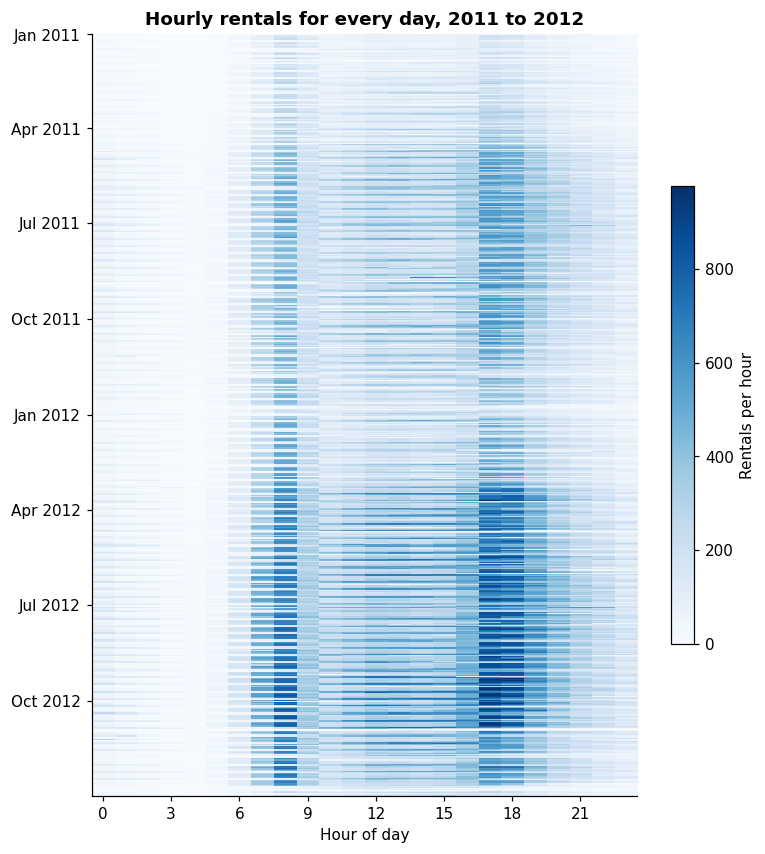

In [4]:
fig, ax = plt.subplots(figsize=(8, 9))
dates = mdates.date2num(X.index.to_pydatetime())
im = ax.imshow(X.values, aspect="auto", cmap="Blues", interpolation="nearest",
               extent=[-0.5, 23.5, dates[-1] + 0.5, dates[0] - 0.5])
ax.yaxis_date()
ax.yaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set(title="Hourly rentals for every day, 2011 to 2012", xlabel="Hour of day",
       xticks=range(0, 24, 3))
ax.grid(False)
fig.colorbar(im, ax=ax, label="Rentals per hour", shrink=0.6)
plt.show()

**What the heatmap shows.**

- **Two vertical dark bands at about 8 a.m. and 5 to 6 p.m.** on most days: the commuting peaks of working days.
- **Rows without those bands** have a broad midday block instead: weekends and holidays.
- **Everything gets darker from 2011 to 2012**: the growth found in Step 1. This is why Step 3 must separate a day's shape from its level.
- **Pale horizontal stripes** cutting across the pattern: days with unusually low demand, such as storms. These are what the project wants to detect.

The commuting versus leisure split can also be checked directly by averaging the profiles of working and non-working days:

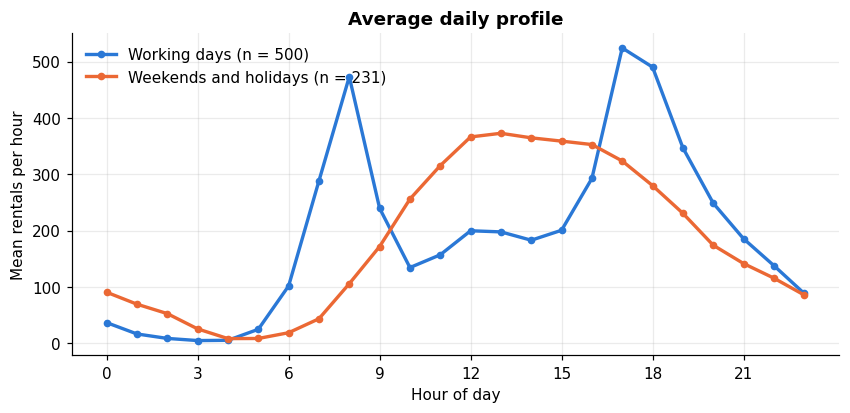

In [5]:
working = day_orig.workingday.reindex(X.index) == 1
mean_work, mean_free = X[working].mean(), X[~working].mean()

fig, ax = plt.subplots(figsize=(9, 3.8))
hours = np.arange(24)
ax.plot(hours, mean_work.values, color=BLUE, linewidth=2.2, marker="o", markersize=4,
        label=f"Working days (n = {working.sum()})")
ax.plot(hours, mean_free.values, color=ORANGE, linewidth=2.2, marker="o", markersize=4,
        label=f"Weekends and holidays (n = {(~working).sum()})")
ax.set(title="Average daily profile", xlabel="Hour of day", ylabel="Mean rentals per hour",
       xticks=range(0, 24, 3))
ax.legend(frameon=False, loc="upper left")
plt.show()

The two shapes are clearly different, which supports clustering on profiles. But an average hides the spread: the project's question is whether *individual* days follow these two calendar labels, or whether there are more (or different) day types. That is answered by the clustering in Step 5.

## 3. Day attributes

One row per day with everything **except** the hourly counts. Weather is summarised from the hourly values, because a day can start clear and end in rain:

| Column | Meaning |
| --- | --- |
| `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday` | Calendar fields from the original data |
| `temp_c_mean`, `atemp_c_mean` | Mean temperature and feels-like temperature (°C) |
| `hum_pct_mean`, `wind_kmh_mean` | Mean humidity (%) and wind speed (km/h) |
| `weathersit_worst` | Worst weather category of the day (1 = clear, 2 = mist, 3 = rain or snow) |
| `bad_weather_daytime_hours` | Hours between 07:00 and 20:00 with weather category 3, when most riding happens |
| `total`, `casual_share` | Daily rentals and the share from casual riders |
| `missing_hours` | Hours absent from the original file (Step 1) |
| `weather_imputed` | Any humidity or feels-like value replaced in Step 1 |

In [6]:
h = hour.assign(
    temp_c=hour.temp * 47 - 8,
    atemp_c=hour.atemp * 66 - 16,
    hum_pct=hour.hum * 100,
    wind_kmh=hour.windspeed * 67,
    bad_daytime=(hour.weathersit == 3) & hour.hr.between(7, 20),
    weather_imputed=hour.hum_imputed | hour.atemp_imputed,
)
g = h.groupby("dteday")

info = day_orig[["season", "yr", "mnth", "holiday", "weekday", "workingday"]].copy()
info["temp_c_mean"] = g.temp_c.mean().round(1)
info["atemp_c_mean"] = g.atemp_c.mean().round(1)
info["hum_pct_mean"] = g.hum_pct.mean().round(1)
info["wind_kmh_mean"] = g.wind_kmh.mean().round(1)
info["weathersit_worst"] = g.weathersit.max()
info["bad_weather_daytime_hours"] = g.bad_daytime.sum()
info["total"] = X.sum(axis=1)
info["casual_share"] = (X_casual.sum(axis=1) / info.total).round(3)
info["missing_hours"] = g.hour_was_missing.sum()
info["weather_imputed"] = g.weather_imputed.any()
info.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
season,731.0,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,731.0,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,731.0,6.52,3.45,1.00,4.00,7.00,10.00,12.00
holiday,731.0,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,731.0,3.00,2.00,0.00,1.00,3.00,5.00,6.00
workingday,731.0,0.68,0.47,0.00,0.00,1.00,1.00,1.00
temp_c_mean,731.0,15.27,8.61,-5.30,7.85,15.40,22.80,32.50
atemp_c_mean,731.0,15.32,10.77,-10.90,6.30,16.20,24.25,39.50
hum_pct_mean,731.0,62.94,14.03,18.80,52.20,62.90,73.00,97.20
wind_kmh_mean,731.0,12.80,5.22,1.50,9.00,12.10,15.70,34.00


## 4. Days that need care in Step 3

Step 3 divides each hourly count by the day's total to get the *shape* of the day. For a day with very few rentals, that shape is mostly noise: 22 rentals spread over 24 hours says little about how people ride. These days are flagged now, so the decision about them is visible and not hidden inside later code.

The threshold below (5% of the median daily total) is a starting point to discuss, not a fixed rule.

In [7]:
LOW_TOTAL = 0.05 * info.total.median()
info["low_total"] = info.total < LOW_TOTAL
print(f"Low-total threshold: {LOW_TOTAL:.0f} rentals per day")
cols = ["total", "missing_hours", "weathersit_worst", "bad_weather_daytime_hours", "workingday"]
info.loc[info.low_total | (info.missing_hours >= 6), cols].sort_values("total")

Low-total threshold: 227 rentals per day


,total,missing_hours,weathersit_worst,bad_weather_daytime_hours,workingday
dteday,,,,,
2012-10-29,22,23,3,14,1
2011-01-27,431,16,3,9,1
2011-01-26,506,8,3,14,1
2011-01-18,683,12,3,5,1
2012-10-30,1096,13,3,12,1
2011-08-27,1115,6,3,10,0
2011-02-22,1450,6,3,0,1
2011-08-28,4334,7,3,2,0


Every day with a long gap of missing hours also had bad weather (category 3) at some point that day, which supports reading these gaps as weather events rather than data faults.

Only one day falls below the threshold: **29 October 2012** (Hurricane Sandy), with 22 rentals. It is clearly an anomaly, but its shape cannot be compared with other days in a meaningful way. Two options for Step 3:

- keep it out of the clustering and report it directly as an anomaly by its level, or
- keep it in and accept that its shape vector is noisy.

The first option is cleaner and easier to justify. The other long-gap days have normal totals and stay in.

## 5. Save

In [8]:
X.to_csv("day_matrix.csv")
X_casual.to_csv("day_matrix_casual.csv")
X_registered.to_csv("day_matrix_registered.csv")
info.to_csv("day_info.csv")

check = pd.read_csv("day_matrix.csv", index_col="dteday", parse_dates=True)
assert check.shape == (731, 24) and (check.values == X.values).all()
print("Saved day_matrix.csv, day_matrix_casual.csv, day_matrix_registered.csv, day_info.csv")
print(f"day_info columns: {list(info.columns)}")

Saved day_matrix.csv, day_matrix_casual.csv, day_matrix_registered.csv, day_info.csv
day_info columns: ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'temp_c_mean', 'atemp_c_mean', 'hum_pct_mean', 'wind_kmh_mean', 'weathersit_worst', 'bad_weather_daytime_hours', 'total', 'casual_share', 'missing_hours', 'weather_imputed', 'low_total']


## Summary for the report

- Each day is represented as a 24-value vector of hourly rentals, giving a 731 x 24 matrix whose row sums match the original daily totals exactly.
- The heatmap shows the structure the project relies on: commuting peaks on working days, a midday block on weekends and holidays, growth from 2011 to 2012, and occasional low-demand days that break the pattern.
- Calendar, weather and data-quality information is stored separately in `day_info.csv`, so the clusters are learned from rental behaviour only.
- One day (29 October 2012, Hurricane Sandy) has too few rentals for a meaningful shape and is set aside for Step 3.

**Next, Step 3:** confirm the trend with seasonal-trend decomposition and split each day into shape (share of the day's rentals per hour) and level (total relative to a 30-day rolling median).